In [1]:
#Importações
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from sklearn.preprocessing import (OneHotEncoder, StandardScaler, MinMaxScaler, PowerTransformer)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans


from Support.config import DADOS_NOVAS_COLS_DROP_COLS
from Support.auxiliary_functions import plot_elbow_silhouette, pairplot, plot_columns_percent_by_cluster

In [2]:
df = pd.read_csv(DADOS_NOVAS_COLS_DROP_COLS)

df.head()

,Education,Marital_Status,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,YearsSinceEnrolled,Age,AgeGroup,MntTotal,MntRegularProds,Children,HasChildren,AcceptedCmpTotal,HasAcceptedCmp,NumTotalPurchases
0,Graduation,Single,58138.0,0,0,58,635,88,546,172,...,1,57,46-60,1617,1529,0,0,0,0,22
1,Graduation,Single,46344.0,1,1,38,11,1,6,2,...,0,60,46-60,27,21,2,1,0,0,4
2,Graduation,Partner,71613.0,0,0,26,426,49,127,111,...,0,49,46-60,776,734,0,0,0,0,20
3,Graduation,Partner,26646.0,1,0,26,11,4,20,10,...,0,30,18-30,53,48,1,1,0,0,6
4,PhD,Partner,58293.0,1,0,94,173,43,118,46,...,0,33,31-45,422,407,1,1,0,0,14


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2205 entries, 0 to 2204
Data columns (total 35 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Education            2205 non-null   object 
 1   Marital_Status       2205 non-null   object 
 2   Income               2205 non-null   float64
 3   Kidhome              2205 non-null   int64  
 4   Teenhome             2205 non-null   int64  
 5   Recency              2205 non-null   int64  
 6   MntWines             2205 non-null   int64  
 7   MntFruits            2205 non-null   int64  
 8   MntMeatProducts      2205 non-null   int64  
 9   MntFishProducts      2205 non-null   int64  
 10  MntSweetProducts     2205 non-null   int64  
 11  MntGoldProds         2205 non-null   int64  
 12  NumDealsPurchases    2205 non-null   int64  
 13  NumWebPurchases      2205 non-null   int64  
 14  NumCatalogPurchases  2205 non-null   int64  
 15  NumStorePurchases    2205 non-null   i

In [4]:
numerical_features = df.select_dtypes(include="number").columns
len(numerical_features)

32

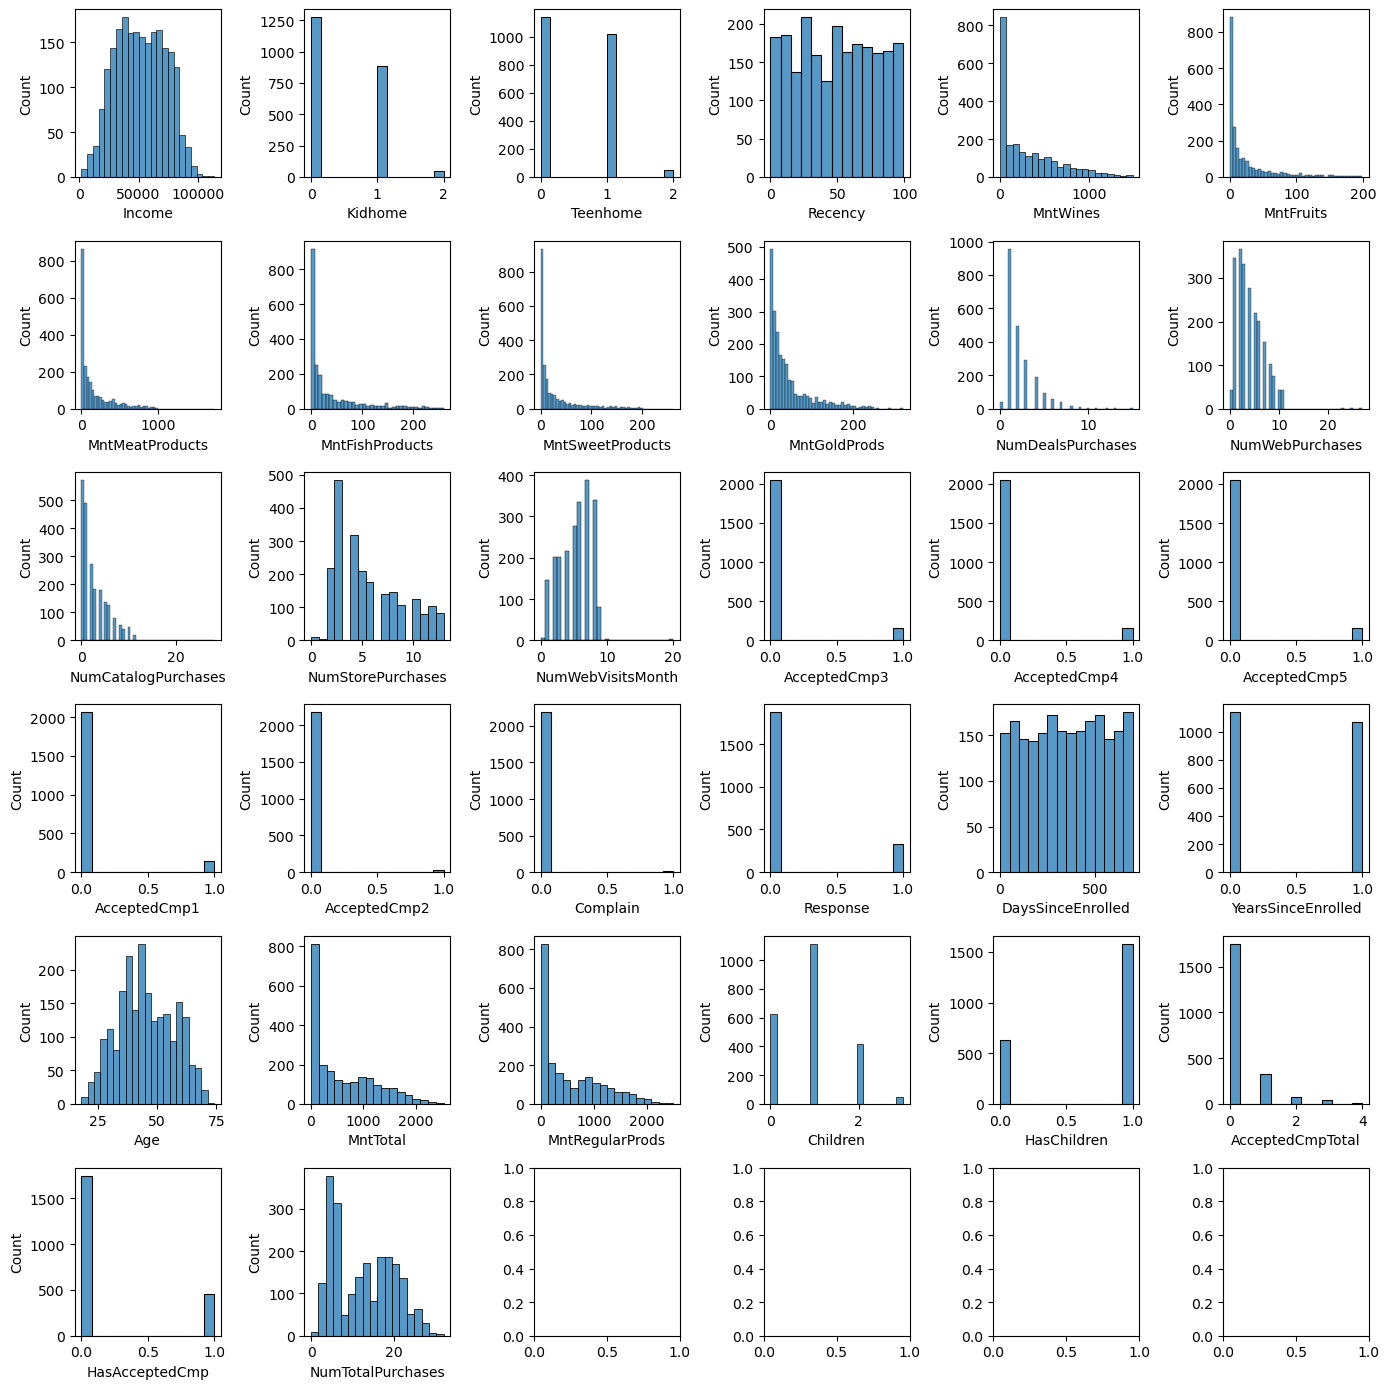

In [5]:
fig, axs = plt.subplots(nrows=6, ncols=6, figsize=(14, 14), tight_layout=True)

for ax, feature in zip(axs.flatten(), numerical_features):
    sns.histplot(x=feature, ax=ax, data=df)

plt.show()

In [7]:
one_hot_cols = ["Education", "Marital_Status", "AgeGroup", "HasChildren", "HasAcceptedCmp", "AcceptedCmp1", "AcceptedCmp2",
                "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5", "Complain", "Response", "Kidhome", "Teenhome", "YearsSinceEnrolled",
                "Children", "AcceptedCmpTotal"]

standard_cols = ["Income", "Age"]

power_cols = df.columns[df.columns.str.startswith("Mnt") | df.columns.str.startswith("Num")].tolist()

minmax_cols = [col for col in df.columns if col not in one_hot_cols + standard_cols + power_cols]

- Separe as colunas que receberão o One Hot Encoder, o Standar Scaler, o Power Transform e por fim as colunas que receberão o Min Max Scaler
- Crie o pré-processamento e treine o df com ele
- Crie um df_scaled que recebe o treinamento anterior e o get_feature_names_out do pré-processamento
- Crie uma variável que recebe o df anterior sem as colunas que receberam o One Hot encoder
- Crie os histogrmas dessas colunas
- Use a função plot_elbow_silhouette das funções auxiliares com o df anterior
- Use o Pipeline com o pré-processamneto e o Kmeans com random_state e n_init 10, depois treine o df original com ele
- Crie df_clustered que é uma cópia do df original, depois crie uma coluna nele chamada cluster que recebe o labels_ do clustering do pipeline
- Crie uma variável para colunas para análise formada por "Income", "Recency", "DaysSinceEnrolled", "Age" e "MntTotal" e use a função pairplot das funções auxiliares com o cluster com ohue
- Crie boxplots da coluna cluster por cada coluna do df_clustered
-clustered e mostrando a média
- Crie as seguintes variáveis:
columns = ["HasChildren", "Marital_Status", "Education", "HasAcceptedCmp", "Response", "YearsSinceEnrolled"]
e
cluster_diff_cols = ["MntTotal", "Income"]
- Crie boxplots da coluna cluster pela posição 0 da cluster_diff_cols (MntTotal), usando o data como df_clustered, mostrando a média e usando cala coluna da variável columns criada anteriormente como hue
- Repita o anterior com a posição 1
- Use a função plot_columns_percent_hue_cluster das funções auxiliares usando o df_clustered e as columns criadas antes na variável
- Repita o plot_columns_percent_hue_cluster com as colunas de AcceptedCmpTotal  e AgeGroup separadamente